# UTS Pembelajaran Mesin 
**NIM:** 202431057 | **Nama:** Hana Malidha Hasan | **Kelas:** E |
**Dataset:** 2 | **Algoritma:** Regresi Linear & KNN

### Import library

In [1]:
#202431057_HANA MALIDHA HASAN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_squared_error, mean_absolute_error,
    r2_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
import warnings; warnings.filterwarnings("ignore")

NIM = "202431057"
NAMA = "HANA MALIDHA HASAN"
SEED = 42
sns.set_style("whitegrid")
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)


print("Library siap digunakan.", NIM, "-", NAMA)

Library siap digunakan. 202431057 - HANA MALIDHA HASAN


### Memuat dataset

In [2]:
#202431057_HANA MALIDHA HASAN
df = pd.read_csv("02_diabetes.csv")
print("Jumlah baris, kolom :", df.shape)
print()
df.info()
df.head()

Jumlah baris, kolom : (100000, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### Statistik deskriptif, missing value, dan data duplikat

In [3]:
#202431057_HANA MALIDHA HASAN
print("Missing value per kolom:"); print(df.isna().sum().to_string())
print("\nJumlah baris duplikat :", df.duplicated().sum())
print("Kategori gender       :", df["gender"].unique().tolist())
print("Kategori smoking      :", df["smoking_history"].unique().tolist())
df.describe().T.round(2)

Missing value per kolom:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0

Jumlah baris duplikat : 3854
Kategori gender       : ['Female', 'Male', 'Other']
Kategori smoking      : ['never', 'No Info', 'current', 'former', 'ever', 'not current']


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.89,22.52,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.32,6.64,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.53,1.07,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.06,40.71,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.08,0.28,0.00,0.00,0.00,0.00,1.00


# EDA
### Distribusi Variabel Target

0    91500
1     8500
0    91.5
1     8.5


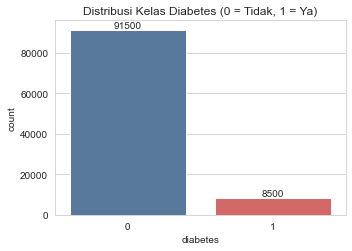

In [4]:
#202431057_HANA MALIDHA HASAN
cnt = df["diabetes"].value_counts()
print(cnt.to_string()); print((cnt / len(df) * 100).round(2).to_string())
fig, ax = plt.subplots(figsize=(5, 3.6))
sns.countplot(x="diabetes", data=df, palette=["#4C78A8", "#E45756"], ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribusi Kelas Diabetes (0 = Tidak, 1 = Ya)")
plt.tight_layout(); plt.show()

### Distribusi Variabel Numerik

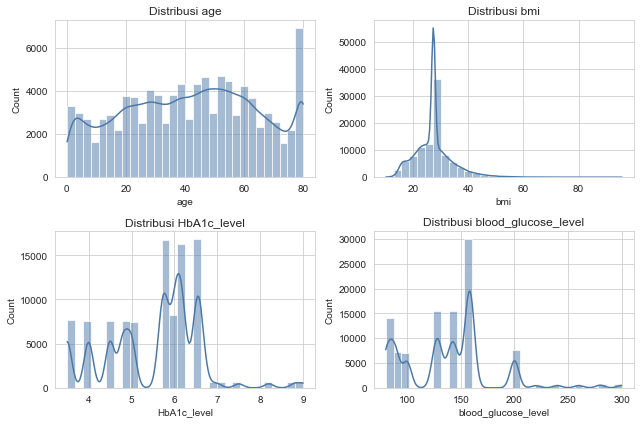

In [5]:
#202431057_HANA MALIDHA HASAN
num_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=30, kde=True, color="#4C78A8", ax=ax)
    ax.set_title(f"Distribusi {c}")
plt.tight_layout(); plt.show()

### Boxplot fitur numerik terhadap diabetes dan deteksi outlier¶

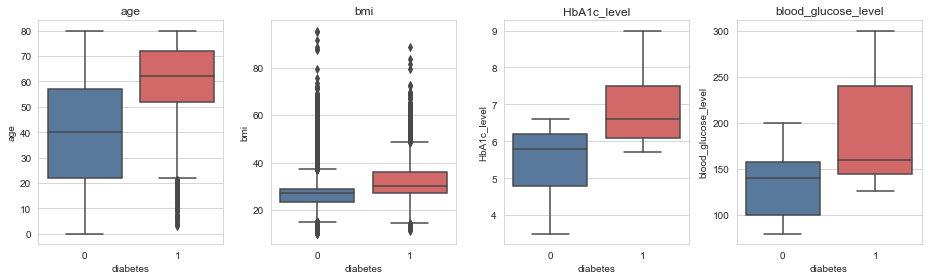

age                    outlier (IQR):      0 (0.00%)
bmi                    outlier (IQR):   7086 (7.09%)
HbA1c_level            outlier (IQR):   1315 (1.31%)
blood_glucose_level    outlier (IQR):   2038 (2.04%)


In [6]:
#202431057_HANA MALIDHA HASAN
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x="diabetes", y=c, data=df, palette=["#4C78A8", "#E45756"], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c:22s} outlier (IQR): {n:6d} ({n/len(df)*100:.2f}%)")

### Fitur kategorikal terhadap proporsi diabetes

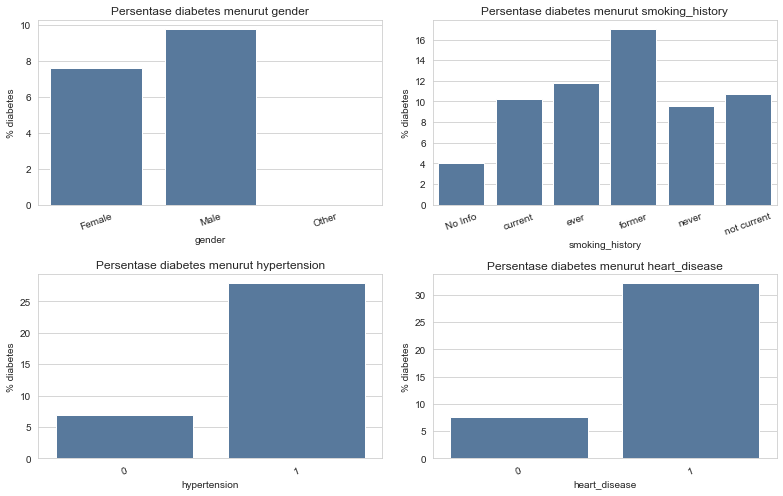

In [7]:
#202431057_HANA MALIDHA HASAN
cat_cols = ["gender", "smoking_history", "hypertension", "heart_disease"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)["diabetes"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, color="#4C78A8", ax=ax)
    ax.set_title(f"Persentase diabetes menurut {c}"); ax.set_ylabel("% diabetes")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### Matriks korelasi

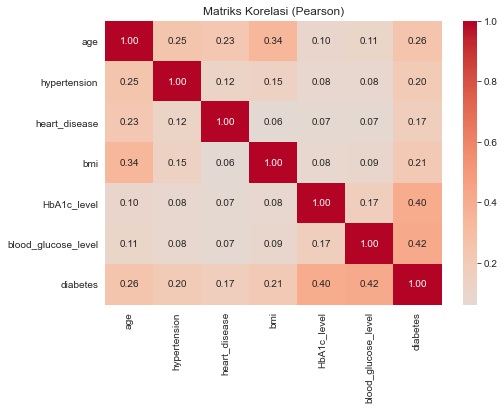

blood_glucose_level    0.420
HbA1c_level            0.401
age                    0.258
bmi                    0.214
hypertension           0.198
heart_disease          0.172


In [8]:
#202431057_HANA MALIDHA HASAN
corr = df.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(7.5, 5.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriks Korelasi (Pearson)")
plt.tight_layout(); plt.show()
print(corr["diabetes"].drop("diabetes").sort_values(ascending=False).round(3).to_string())

# Preprocessing 
### Hapus duplikat dan encoding kategorikal

In [9]:
#202431057_HANA MALIDHA HASAN
n_awal = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Baris sebelum: {n_awal} | sesudah: {len(df_clean)} | dihapus: {n_awal - len(df_clean)}")

# One-hot encoding untuk fitur kategorikal nominal (drop_first agar tidak multikolinear)
df_enc = pd.get_dummies(df_clean, columns=["gender", "smoking_history"], drop_first=True, dtype=int)
print("Bentuk data setelah encoding:", df_enc.shape)
print("Distribusi target (%):"); print((df_enc["diabetes"].value_counts(normalize=True) * 100).round(2).to_string())
df_enc.head()

Baris sebelum: 100000 | sesudah: 96146 | dihapus: 3854
Bentuk data setelah encoding: (96146, 14)
Distribusi target (%):
0    91.18
1     8.82


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,0,0,0,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,0,1,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,0,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,0,1,0,1,0,0,0,0


### Pembagian data latih/uji dan standardisasi¶

In [10]:
#202431057_HANA MALIDHA HASAN
X = df_enc.drop(columns="diabetes")
y = df_enc["diabetes"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit hanya pada data latih (hindari data leakage)
X_test_s = scaler.transform(X_test)

print("X_train:", X_train_s.shape, "| X_test:", X_test_s.shape)
print("Proporsi diabetes train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))
print("Mean fitur (train, setelah scaling) ~", np.round(X_train_s.mean(), 4),
      "| Std ~", np.round(X_train_s.std(), 4))

X_train: (76916, 13) | X_test: (19230, 13)
Proporsi diabetes train: 0.088 | test: 0.088
Mean fitur (train, setelah scaling) ~ 0.0 | Std ~ 1.0


# Model 1: Regresi Linear
### Pelatihan dan evaluasi regresi

In [11]:
#202431057_HANA MALIDHA HASAN
lin = LinearRegression()
lin.fit(X_train_s, y_train)
y_pred_cont = lin.predict(X_test_s)          # keluaran kontinu (skor)

print("== Metrik regresi pada data uji ==")
print("MSE  :", round(mean_squared_error(y_test, y_pred_cont), 4))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, y_pred_cont)), 4))
print("MAE  :", round(mean_absolute_error(y_test, y_pred_cont), 4))
print("R2   :", round(r2_score(y_test, y_pred_cont), 4))
print("\nIntercept:", round(lin.intercept_, 4))
coef = pd.Series(lin.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print(coef.round(4).to_string())

== Metrik regresi pada data uji ==
MSE  : 0.0519
RMSE : 0.2279
MAE  : 0.1573
R2   : 0.3542

Intercept: 0.0882
blood_glucose_level            0.0944
HbA1c_level                    0.0891
age                            0.0323
bmi                            0.0268
hypertension                   0.0252
heart_disease                  0.0230
gender_Male                    0.0076
smoking_history_former         0.0065
smoking_history_never          0.0038
smoking_history_not current    0.0025
smoking_history_current        0.0013
smoking_history_ever           0.0011
gender_Other                  -0.0005


### konversi ke kelas dan akurasi¶

Akurasi Regresi Linear : 0.9396 (93.96%)

Confusion matrix [[TN, FP], [FN, TP]]:
[[17525     9]
 [ 1152   544]]

Baseline kelas mayoritas: 0.9118 

                precision    recall  f1-score   support

Tidak diabetes     0.9383    0.9995    0.9679     17534
      Diabetes     0.9837    0.3208    0.4838      1696

      accuracy                         0.9396     19230
     macro avg     0.9610    0.6601    0.7259     19230
  weighted avg     0.9423    0.9396    0.9252     19230



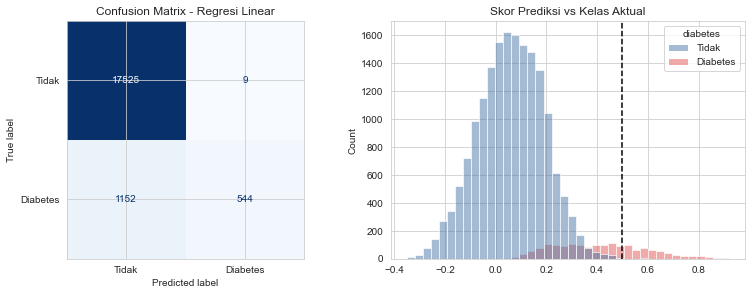

In [12]:
#202431057_HANA MALIDHA HASAN
y_pred_lin = (y_pred_cont >= 0.5).astype(int)   # ambang keputusan 0,5

acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Akurasi Regresi Linear : {acc_lin:.4f} ({acc_lin*100:.2f}%)\n")
print("Confusion matrix [[TN, FP], [FN, TP]]:"); print(confusion_matrix(y_test, y_pred_lin)); print()
print("Baseline kelas mayoritas: %.4f" % (1 - y_test.mean()), "\n")
print(classification_report(y_test, y_pred_lin, target_names=["Tidak diabetes", "Diabetes"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_lin),
    display_labels=["Tidak", "Diabetes"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix - Regresi Linear")
sns.histplot(x=y_pred_cont, hue=y_test.map({0: "Tidak", 1: "Diabetes"}), bins=40,
             stat="count", ax=axes[1], palette=["#4C78A8", "#E45756"])
axes[1].axvline(0.5, color="k", ls="--"); axes[1].set_title("Skor Prediksi vs Kelas Aktual")
plt.tight_layout(); plt.show()

# Model 2
### KNN baseline (k = 5)

In [13]:
#202431057_HANA MALIDHA HASAN
knn0 = KNeighborsClassifier(n_neighbors=5)
knn0.fit(X_train_s, y_train)
y_pred_knn0 = knn0.predict(X_test_s)
print(f"Akurasi KNN baseline (k=5): {accuracy_score(y_test, y_pred_knn0):.4f}")
print(f"Recall kelas diabetes     : {recall_score(y_test, y_pred_knn0):.4f}")

Akurasi KNN baseline (k=5): 0.9592
Recall kelas diabetes     : 0.6167


### Tuning hyperparameter KNN dengan GridSearchCV

Parameter terbaik : {'n_neighbors': 15, 'weights': 'uniform'}
Akurasi CV terbaik: 0.9587
param_n_neighbors param_weights  mean_test_score
               15       uniform           0.9587
                9       uniform           0.9587
               15      distance           0.9585
                5       uniform           0.9581
                9      distance           0.9581
               21      distance           0.9579


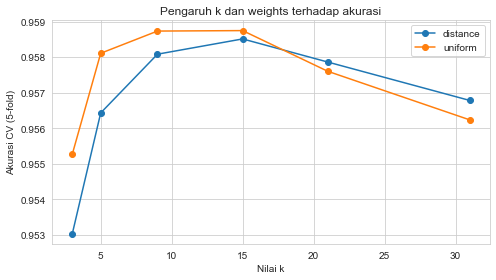

In [14]:
#202431057_HANA MALIDHA HASAN
param_grid = {"n_neighbors": [3, 5, 9, 15, 21, 31],
              "weights": ["uniform", "distance"]}
gs = GridSearchCV(KNeighborsClassifier(), param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                  scoring="accuracy", n_jobs=2)
gs.fit(X_train_s, y_train)
print("Parameter terbaik :", gs.best_params_)
print(f"Akurasi CV terbaik: {gs.best_score_:.4f}")

res = pd.DataFrame(gs.cv_results_)
print(res[["param_n_neighbors", "param_weights", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(6).round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
for w, g in res.groupby("param_weights"):
    ax.plot(g["param_n_neighbors"].astype(int), g["mean_test_score"], marker="o", label=w)
ax.set_xlabel("Nilai k"); ax.set_ylabel("Akurasi CV (5-fold)")
ax.set_title("Pengaruh k dan weights terhadap akurasi"); ax.legend()
plt.tight_layout(); plt.show()

### Evaluasi KNN terbaik pada data uji

Akurasi KNN (tuned) : 0.9603 (96.03%)

Confusion matrix [[TN, FP], [FN, TP]]:
[[17492    42]
 [  721   975]]

                precision    recall  f1-score   support

Tidak diabetes     0.9604    0.9976    0.9787     17534
      Diabetes     0.9587    0.5749    0.7188      1696

      accuracy                         0.9603     19230
     macro avg     0.9596    0.7862    0.8487     19230
  weighted avg     0.9603    0.9603    0.9557     19230



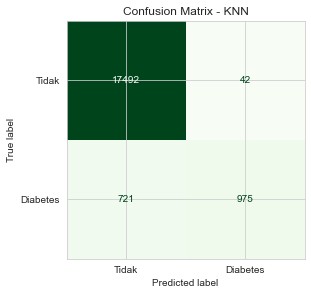

In [15]:
#202431057_HANA MALIDHA HASAN
knn = gs.best_estimator_
y_pred_knn = knn.predict(X_test_s)
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"Akurasi KNN (tuned) : {acc_knn:.4f} ({acc_knn*100:.2f}%)\n")
print("Confusion matrix [[TN, FP], [FN, TP]]:"); print(confusion_matrix(y_test, y_pred_knn)); print()
print(classification_report(y_test, y_pred_knn, target_names=["Tidak diabetes", "Diabetes"], digits=4))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn),
    display_labels=["Tidak", "Diabetes"]).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Confusion Matrix - KNN")
plt.tight_layout(); plt.show()

### KNN dengan k sesuai nomor PC (k = 9)

In [16]:
#202431057_HANA MALIDHA HASAN
K_TARGET = 9   # Nomor PC praktikum
knn_pc = KNeighborsClassifier(n_neighbors=K_TARGET)
knn_pc.fit(X_train_s, y_train)
y_pred_pc = knn_pc.predict(X_test_s)
print(f"Nilai K yang digunakan : {K_TARGET}")
print(f"Akurasi KNN (k = {K_TARGET})   : {accuracy_score(y_test, y_pred_pc):.4f}\n")
print("Confusion matrix [[TN, FP], [FN, TP]]:"); print(confusion_matrix(y_test, y_pred_pc)); print()
print(classification_report(y_test, y_pred_pc, target_names=["Tidak diabetes", "Diabetes"], digits=4))

Nilai K yang digunakan : 9
Akurasi KNN (k = 9)   : 0.9595

Confusion matrix [[TN, FP], [FN, TP]]:
[[17452    82]
 [  696  1000]]

                precision    recall  f1-score   support

Tidak diabetes     0.9616    0.9953    0.9782     17534
      Diabetes     0.9242    0.5896    0.7199      1696

      accuracy                         0.9595     19230
     macro avg     0.9429    0.7925    0.8491     19230
  weighted avg     0.9583    0.9595    0.9554     19230



# Perbandingan Regresi Linear vs KNN

                   Akurasi  Precision  Recall  F1-score  ROC-AUC
Model                                                           
Regresi Linear      0.9396     0.9837  0.3208    0.4838   0.9518
KNN (k=15, tuned)   0.9603     0.9587  0.5749    0.7188   0.9406
KNN (k=9, No. PC)   0.9595     0.9242  0.5896    0.7199   0.9228


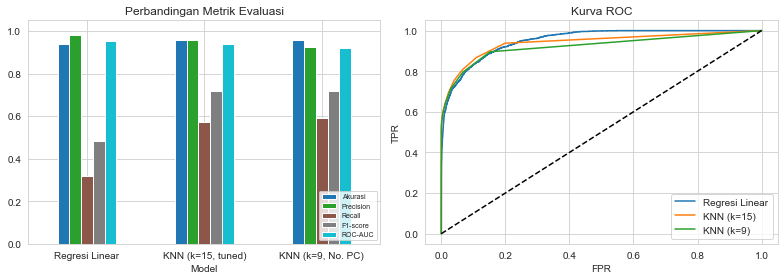

In [17]:
#202431057_HANA MALIDHA HASAN
proba_knn = knn.predict_proba(X_test_s)[:, 1]
rows = []
proba_pc = knn_pc.predict_proba(X_test_s)[:, 1]
for name, yp, score in [("Regresi Linear", y_pred_lin, y_pred_cont), ("KNN (k=15, tuned)", y_pred_knn, proba_knn), ("KNN (k=9, No. PC)", y_pred_pc, proba_pc)]:
    rows.append({"Model": name,
                 "Akurasi": accuracy_score(y_test, yp),
                 "Precision": precision_score(y_test, yp),
                 "Recall": recall_score(y_test, yp),
                 "F1-score": f1_score(y_test, yp),
                 "ROC-AUC": roc_auc_score(y_test, score)})
hasil = pd.DataFrame(rows).set_index("Model").round(4)
print(hasil.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hasil.plot(kind="bar", ax=axes[0], rot=0, colormap="tab10"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Perbandingan Metrik Evaluasi"); axes[0].legend(fontsize=7, loc="lower right")
for name, score in [("Regresi Linear", y_pred_cont), ("KNN (k=15)", proba_knn), ("KNN (k=9)", proba_pc)]:
    fpr, tpr, _ = roc_curve(y_test, score); axes[1].plot(fpr, tpr, label=name)
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
axes[1].set_title("Kurva ROC"); axes[1].legend()
plt.tight_layout(); plt.show()